In [24]:
import matplotlib.pyplot as plt
from src.optimize import run_optimization
import numpy as np

### 1. Esecuzione dell'Algoritmo NSGA-II e Visualizzazione del Fronte di Pareto
In questa sezione viene avviata l'ottimizzazione multiobiettivo tramite l'algoritmo **NSGA-II** (configurato con popolazione di 40 e 25 generazioni). Successivamente, le soluzioni uniche ottenute vengono estratte e visualizzate su un piano bidimensionale per mostrare il trade-off tra la capacità della batteria e l'energia prelevata dalla rete.

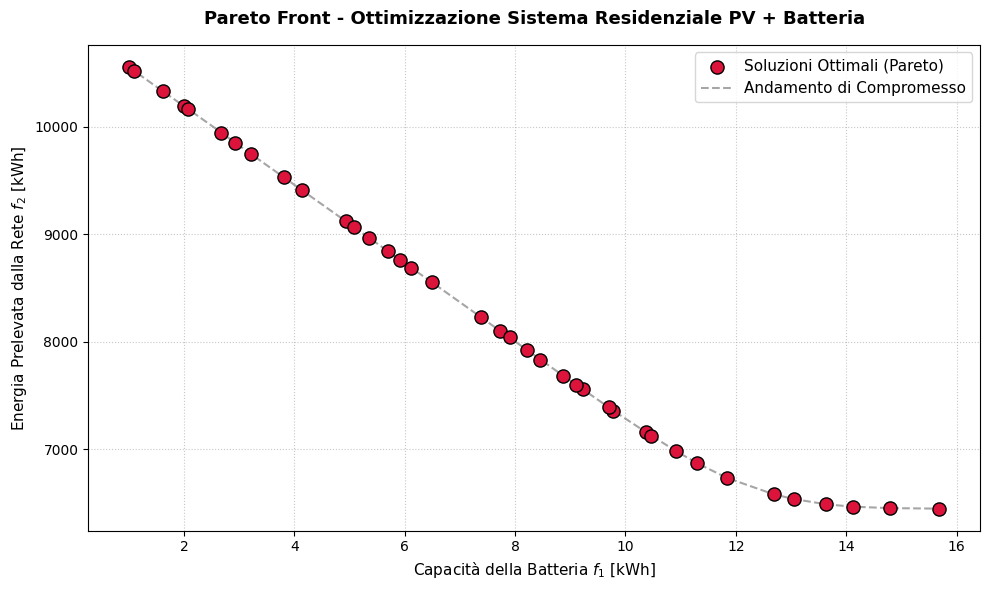

In [25]:
pareto_front = run_optimization(pop_size=40, n_gen = 25)

unique_solutions = {}
for ind in pareto_front:
    cap = round(ind[0],2)
    grid = round(ind.fitness.values[1],2)
    unique_solutions[cap] = grid

capacities = list(unique_solutions.keys())
grid_purchases = list(unique_solutions.values())

plt.figure(figsize = (10,6))
plt.scatter(capacities, grid_purchases, color = 'crimson', s=90, edgecolors='black',zorder=3,label="Soluzioni Ottimali (Pareto)")

sorted_indices = sorted(range(len(capacities)), key= lambda k: capacities[k])
sorted_cap = [capacities[i] for i in sorted_indices]
sorted_grid = [grid_purchases[i] for i in sorted_indices]

plt.plot(sorted_cap, sorted_grid, linestyle = '--', color = "gray", alpha=0.7, zorder=2, label="Andamento di Compromesso")

plt.title("Pareto Front - Ottimizzazione Sistema Residenziale PV + Batteria", fontsize = 13, fontweight="bold", pad=15)
plt.xlabel("Capacità della Batteria $f_1$ [kWh]", fontsize=11)
plt.ylabel("Energia Prelevata dalla Rete $f_2$ [kWh]", fontsize = 11)
plt.grid(True, linestyle=":", alpha = 0.7)
plt.legend(fontsize=11, loc="upper right")

plt.tight_layout()
plt.show()


### 2. Validazione Quantitativa: Calcolo dell'Hypervolume (HV)
Per valutare la bontà del Fronte di Pareto generato (in termini di convergenza e diversità delle soluzioni), viene calcolata la metrica dell'**Hypervolume**. L'indicatore misura lo spazio dominato dal fronte rispetto a un punto di riferimento pessimistico ($ref\_x, ref\_y$), fornendo un riscontro quantitativo delle prestazioni dell'algoritmo evolutivo.

In [26]:
F = np.array([ind.fitness.values for ind in pareto_front])

sorted_indices = np.argsort(F[:, 0])
F_sorted = F[sorted_indices]

ref_x = 2.0 * np.max(F[:, 0])
ref_y = 2.0 * np.max(F[:, 1])

hv_value = 0.0
prev_x = ref_x

for i, point in enumerate(F_sorted):
    x, y = point[0], point[1]
    width = prev_x - x
    height = ref_y - y
    hv_value += width *  height
    prev_x = x

print(f"Hypervolume: {hv_value:.4f}")

Hypervolume: 127734.9429


### 3. Analisi di Compromesso: Individuazione del "Gomito" (Knee Point)
Dal momento che il Fronte di Pareto offre molteplici configurazioni ottime, viene implementato un algoritmo geometrico per individuare automaticamente il **Knee Point** (il punto di massimo "gomito"). Questa soluzione rappresenta il miglior compromesso ingegneristico, permettendo di scartare gli estremi non realistici e di isolare la configurazione ideale e le relative alternative vicine.

In [27]:
costo = 1200.0
capex = np.array([ind[0]* costo for ind in pareto_front])

sorted_indices = np.argsort(F[:, 0])
F_sorted = F[sorted_indices]
capex_sorted =  capex[sorted_indices]
pareto_sorted = [pareto_front[i] for i in sorted_indices]

p1 = F_sorted[0]
p2 = F_sorted[-1]

line_vec = p2 - p1
line_vec_norm = line_vec / np.linalg.norm(line_vec)

distances = []
for point in F_sorted:
    v = point - p1
    parallel = np.dot(v, line_vec_norm) * line_vec_norm
    orthogonal = v - parallel
    distances.append(np.linalg.norm(orthogonal))

knee_local_idx = np.argmax(distances)
best_original_idx = sorted_indices[knee_local_idx]

print("--- ANALISI DEL FRONTE DI PARETO: ZONA DI COMPROMESSO (GOMITO) ---")
print(f"Soluzione ottimale di compromesso identificata: Soluzione {best_original_idx + 1}")
print(f"-> CAPEX di investimento: € {capex[best_original_idx]:,.2f}")
print(f"-> Valori obiettivi (Costo / Deficit): {F[best_original_idx]}")

range_indices = [sorted_indices[max(0, knee_local_idx - 1)], best_original_idx, sorted_indices[min(len(F_sorted) - 1, knee_local_idx+1 )]]

print("\nRange delle migliori soluzioni vicine al gomito:")
for idx in range_indices:
    print(f"- Soluzione {idx + 1}: CAPEX € {capex[idx]:,.2f} | Obiettivi: {F[idx]}")

--- ANALISI DEL FRONTE DI PARETO: ZONA DI COMPROMESSO (GOMITO) ---
Soluzione ottimale di compromesso identificata: Soluzione 10
-> CAPEX di investimento: € 13,553.75
-> Valori obiettivi (Costo / Deficit): [  11.29479444 6871.08506413]

Range delle migliori soluzioni vicine al gomito:
- Soluzione 11: CAPEX € 13,093.56 | Obiettivi: [  10.91129838 6983.99958477]
- Soluzione 10: CAPEX € 13,553.75 | Obiettivi: [  11.29479444 6871.08506413]
- Soluzione 8: CAPEX € 14,209.79 | Obiettivi: [  11.84148772 6732.25918335]
